# Basic CTC Evidence Accumulation Analysis

This notebook loads the saved timestep-level CTC evidence summaries from an SNN+CTC validation or inference run and gives a first simple view of how evidence evolves over time.

It does not retrain anything, modify the model, or add lag analyses. It only inspects the saved signals.

In [1]:
from pathlib import Path
import pickle

import matplotlib.pyplot as plt
import numpy as np
import torch

## Config

Set `CTC_EVIDENCE_PATH` to a specific saved file if needed. If left as `None`, the notebook will try to find the most recent `ctc_evidence/*.pt` file under `model_training/logs/`.

In [6]:
CTC_EVIDENCE_PATH = Path("../logs/snn/2026-04-05/2026-04-05_23-15-25_453530_snn_pid574592/ctc_evidence/validation_run_0008.pt")

EXAMPLE_TRIAL_INDICES = [0, 1, 2]

TOP_PEAK_MIN = 0.35
BLANK_VALLEY_MAX = 0.60
MIN_PEAK_DISTANCE = 3

NORMALIZED_TIME_BINS = 100

In [7]:
repo_root = Path.cwd()

if CTC_EVIDENCE_PATH is None:
    candidates = sorted(repo_root.glob('model_training/logs/**/ctc_evidence/*.pt'))
    if not candidates:
        candidates = sorted(repo_root.glob('**/ctc_evidence/*.pt'))
    if not candidates:
        raise FileNotFoundError('No saved ctc_evidence .pt files were found. Set CTC_EVIDENCE_PATH manually.')
    ctc_evidence_path = candidates[-1]
else:
    ctc_evidence_path = Path(CTC_EVIDENCE_PATH)

print(f'Using evidence file: {ctc_evidence_path}')

Using evidence file: ../logs/snn/2026-04-05/2026-04-05_23-15-25_453530_snn_pid574592/ctc_evidence/validation_run_0008.pt


## Load And Inspect Structure

The first step is to inspect what was saved so the rest of the notebook stays explicit and easy to trust.

In [8]:
def load_saved_artifact(path: Path):
    suffix = path.suffix.lower()
    if suffix == '.pt':
        return torch.load(path, map_location='cpu', weights_only=False)
    if suffix == '.pkl':
        with open(path, 'rb') as f:
            return pickle.load(f)
    if suffix == '.npz':
        npz = np.load(path, allow_pickle=True)
        return {key: npz[key] for key in npz.files}
    raise ValueError(f'Unsupported file type: {path.suffix}')


def summarize_value(name, value, indent=0):
    prefix = '  ' * indent
    if isinstance(value, dict):
        print(f'{prefix}{name}: dict with keys={list(value.keys())}')
        return
    if isinstance(value, list):
        print(f'{prefix}{name}: list len={len(value)}')
        if len(value) > 0:
            first = value[0]
            if isinstance(first, dict):
                print(f'{prefix}  first item keys={list(first.keys())}')
            elif isinstance(first, np.ndarray):
                print(f'{prefix}  first item shape={first.shape}, dtype={first.dtype}')
            else:
                print(f'{prefix}  first item type={type(first).__name__}')
        return
    if isinstance(value, np.ndarray):
        print(f'{prefix}{name}: ndarray shape={value.shape}, dtype={value.dtype}')
        return
    if torch.is_tensor(value):
        print(f'{prefix}{name}: tensor shape={tuple(value.shape)}, dtype={value.dtype}')
        return
    print(f'{prefix}{name}: {type(value).__name__} -> {value}')


artifact = load_saved_artifact(ctc_evidence_path)
print('Top-level keys:')
for key, value in artifact.items():
    summarize_value(key, value)

trials = artifact['trials']
print('\nFirst trial structure:')
for key, value in trials[0].items():
    summarize_value(key, value, indent=1)

Top-level keys:
split: str -> validation
run_index: int -> 8
phoneme_classes: list len=41
  first item type=str
trials: list len=1426
  first item keys=['trial_id', 'day_index', 'block_num', 'trial_num', 'output_length', 'blank_probability', 'top_non_blank_probability', 'top_non_blank_class', 'argmax_class', 'entropy', 'target_sequence', 'decoded_sequence', 'transcription']

First trial structure:
  trial_id: str -> day_01_block_0008_trial_0000
  day_index: int -> 1
  block_num: int -> 8
  trial_num: int -> 0
  output_length: int -> 227
  blank_probability: ndarray shape=(227,), dtype=float32
  top_non_blank_probability: ndarray shape=(227,), dtype=float32
  top_non_blank_class: ndarray shape=(227,), dtype=int32
  argmax_class: ndarray shape=(227,), dtype=int32
  entropy: ndarray shape=(227,), dtype=float32
  target_sequence: ndarray shape=(36,), dtype=int32
  decoded_sequence: ndarray shape=(37,), dtype=int32
  transcription: str -> You can see the code at this point as well.


The saved trial records should contain the main timestep signals needed for a first CTC evidence view: blank probability, strongest non-blank evidence, argmax class, and entropy.

In [9]:
phoneme_classes = artifact.get('phoneme_classes', None)
print(f'Number of trials: {len(trials)}')
print(f'Number of phoneme classes: {len(phoneme_classes) if phoneme_classes is not None else "unknown"}')

Number of trials: 1426
Number of phoneme classes: 41


## Helpers

These helper functions keep the plots short and make the peak-detection thresholds easy to adjust.

In [10]:
def as_numpy(x):
    if x is None:
        return None
    if torch.is_tensor(x):
        return x.detach().cpu().numpy()
    return np.asarray(x)


def local_maxima(signal, threshold=0.0, min_distance=1):
    signal = np.asarray(signal)
    if signal.size < 3:
        return np.array([], dtype=int)

    candidates = []
    for idx in range(1, len(signal) - 1):
        if signal[idx] >= threshold and signal[idx] >= signal[idx - 1] and signal[idx] >= signal[idx + 1]:
            candidates.append(idx)

    if not candidates:
        return np.array([], dtype=int)

    candidates = sorted(candidates, key=lambda idx: signal[idx], reverse=True)
    selected = []
    for idx in candidates:
        if all(abs(idx - kept) >= min_distance for kept in selected):
            selected.append(idx)
    return np.array(sorted(selected), dtype=int)


def local_minima(signal, threshold=1.0, min_distance=1):
    return local_maxima(-np.asarray(signal), threshold=-threshold, min_distance=min_distance)


def resample_to_bins(signal, n_bins):
    signal = np.asarray(signal, dtype=float)
    if signal.size == 1:
        return np.repeat(signal, n_bins)
    old_x = np.linspace(0.0, 1.0, signal.size)
    new_x = np.linspace(0.0, 1.0, n_bins)
    return np.interp(new_x, old_x, signal)


def argmax_labels(argmax_class, class_names, peak_indices=None):
    if class_names is None:
        return [str(int(x)) for x in argmax_class]
    if peak_indices is None:
        return [class_names[int(x)] for x in argmax_class]
    return [class_names[int(argmax_class[idx])] for idx in peak_indices]


## Example Trials

These plots show a few individual trials over time. In CTC terms, a useful first question is whether non-blank evidence rises in brief peaks while blank probability falls, and whether entropy becomes lower at those moments.

The red markers indicate simple candidate evidence peaks based on local maxima of top non-blank probability. The black `x` markers indicate local minima of blank probability. The secondary axis shows the argmax class id over time, and detected non-blank peaks are labeled with the corresponding argmax phoneme.

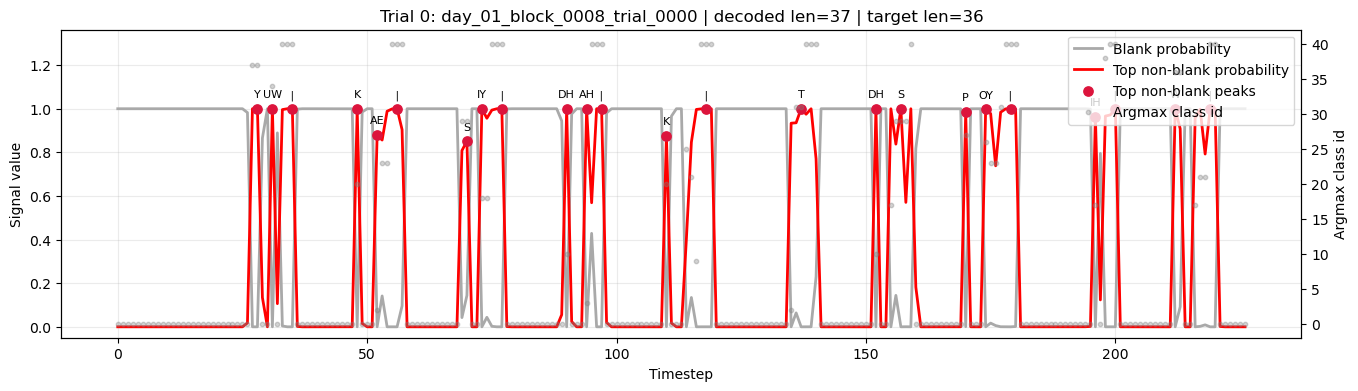

  top non-blank peaks: [28, 31, 35, 48, 52, 56, 70, 73, 77, 90, 94, 97, 110, 118, 137, 152, 157, 170, 174, 179, 196, 200, 212, 219]
  blank minima: [28, 31, 35, 48, 52, 56, 69, 73, 77, 90, 94, 97, 110, 114, 118, 137, 152, 157, 170, 174, 179, 196, 200, 212, 216, 219]
  decoded_sequence: [37 34 40 20  2 23 40 29 18 40 10  3 40 20 25 21  9 40  2 31 40 10 17 29
 40 27 26 23 31 40 17 38 40 36 17 21 40]
  target_sequence: [37 34 40 20  2 23 40 29 18 40 10  3 40 20 25  9 40  2 31 40 10 17 29 40
 27 26 23 31 40  2 38 40 36 11 21 40]
  transcription: You can see the code at this point as well.


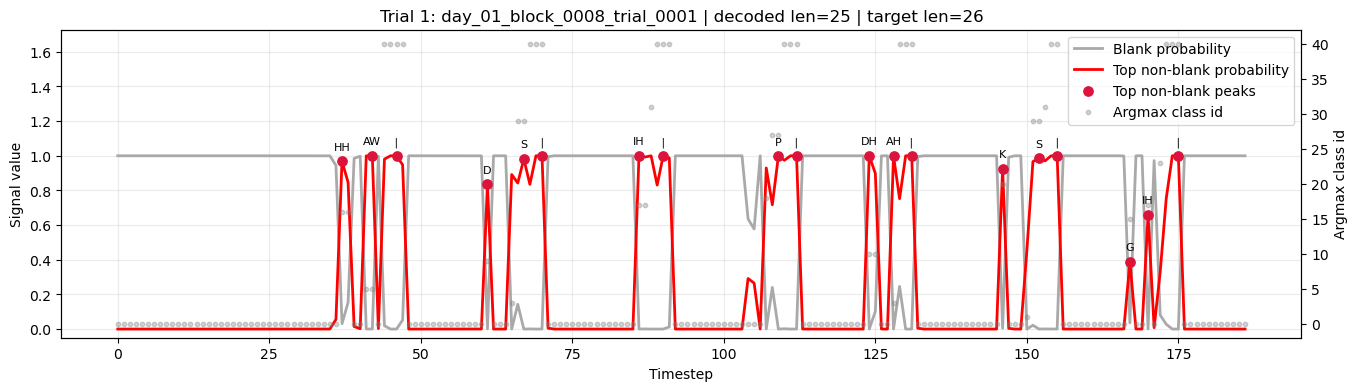

  top non-blank peaks: [37, 42, 46, 61, 67, 70, 86, 90, 109, 112, 124, 128, 131, 146, 152, 155, 167, 170, 175]
  blank minima: [37, 42, 46, 61, 65, 70, 88, 107, 112, 124, 128, 131, 146, 152, 155, 167, 170, 175]
  decoded_sequence: [16  5 40  9  3 29 40 17 31 40 18 27 40 10  3 40 20  1 29 31 40 15 17 23
 40]
  target_sequence: [16  5 40  9  3 38 40 17 31 40 20 18 27 40 10  3 40 20  1 29 31 40  9  5
 23 40]
  transcription: How does it keep the cost down?


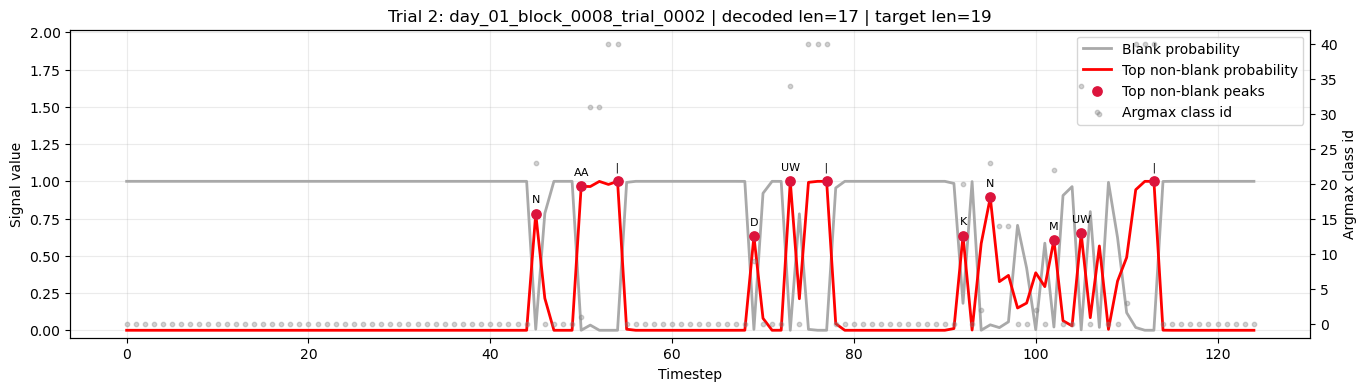

  top non-blank peaks: [45, 50, 54, 69, 73, 77, 92, 95, 102, 105, 113]
  blank minima: [45, 50, 54, 69, 73, 77, 94, 100, 105, 113]
  decoded_sequence: [23  1 31 40  9 34 40 20  2 23 14  2 22 34 30  3 40]
  target_sequence: [23  1 31 40 31 34 40 20  1 23 31 28  3 35 12 30  3 21 40]
  transcription: Not too controversial.


In [20]:
def plot_trial(trial, trial_index):
    blank = as_numpy(trial['blank_probability'])
    top_non_blank = as_numpy(trial['top_non_blank_probability'])
    entropy = as_numpy(trial['entropy'])
    argmax_class = as_numpy(trial['argmax_class'])

    top_peaks = local_maxima(top_non_blank, threshold=TOP_PEAK_MIN, min_distance=MIN_PEAK_DISTANCE)
    blank_valleys = local_minima(blank, threshold=BLANK_VALLEY_MAX, min_distance=MIN_PEAK_DISTANCE)

    t = np.arange(len(blank))
    fig, ax = plt.subplots(figsize=(16, 4))

    ax.plot(t, blank, label='Blank probability', color='darkgray', linewidth=2)
    ax.plot(t, top_non_blank, label='Top non-blank probability', color='red', linewidth=2)
    #ax.plot(t, entropy, label='Entropy', color='tab:green', linewidth=2, alpha=0.85)

    if len(top_peaks) > 0:
        ax.scatter(top_peaks, top_non_blank[top_peaks], color='crimson', s=45, label='Top non-blank peaks', zorder=5)
    #if len(blank_valleys) > 0:
    #    ax.scatter(blank_valleys, blank[blank_valleys], color='black', marker='x', s=45, label='Blank minima', zorder=5)

    ax2 = ax.twinx()
    ax2.scatter(t, argmax_class, color='gray', s=10, alpha=0.35, label='Argmax class id')
    ax2.set_ylabel('Argmax class id')

    if len(top_peaks) > 0 and phoneme_classes is not None:
        peak_labels = argmax_labels(argmax_class, phoneme_classes, top_peaks)
        for peak_idx, label in zip(top_peaks, peak_labels):
            ax.annotate(label, (peak_idx, top_non_blank[peak_idx]), textcoords='offset points', xytext=(0, 8), ha='center', fontsize=8)

    title = f"Trial {trial_index}: {trial.get('trial_id', 'unknown')}"
    if trial.get('decoded_sequence') is not None:
        title += f" | decoded len={len(trial['decoded_sequence'])}"
    if trial.get('target_sequence') is not None:
        title += f" | target len={len(trial['target_sequence'])}"
    ax.set_title(title)
    ax.set_xlabel('Timestep')
    ax.set_ylabel('Signal value')
    ax.set_ylim(-0.05, max(1.05, float(np.nanmax([blank.max(), top_non_blank.max(), entropy.max()])) + 0.05))
    ax.grid(alpha=0.25)

    handles1, labels1 = ax.get_legend_handles_labels()
    handles2, labels2 = ax2.get_legend_handles_labels()
    ax.legend(handles1 + handles2, labels1 + labels2, loc='upper right')
    plt.show()

    print('  top non-blank peaks:', top_peaks.tolist())
    print('  blank minima:', blank_valleys.tolist())
    if trial.get('decoded_sequence') is not None:
        print('  decoded_sequence:', trial['decoded_sequence'])
    if trial.get('target_sequence') is not None:
        print('  target_sequence:', trial['target_sequence'])
    if trial.get('transcription'):
        print('  transcription:', trial['transcription'])


for trial_index in EXAMPLE_TRIAL_INDICES:
    if trial_index >= len(trials):
        print(f'Skipping missing trial index {trial_index}')
        continue
    plot_trial(trials[trial_index], trial_index)

## Aggregate View Across Trials

These plots summarize the overall pattern across trials. Averaging over normalized time gives a coarse first view of whether blank dominates early and non-blank evidence rises later. The histogram shows how many simple candidate evidence peaks each trial contains under the current thresholds.

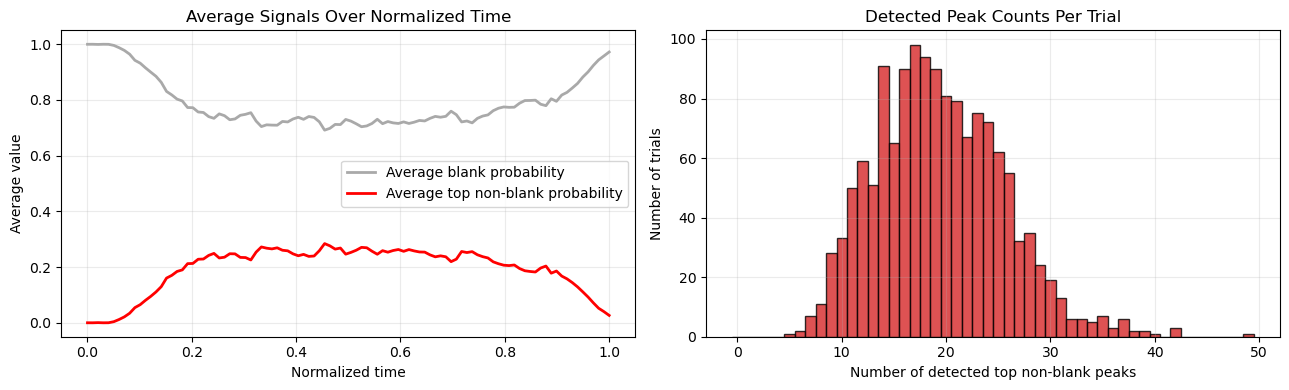

Mean detected peak count per trial: 19.37
Median detected peak count per trial: 19.00


In [21]:
blank_resampled = []
top_non_blank_resampled = []
peak_counts = []

for trial in trials:
    blank = as_numpy(trial['blank_probability'])
    top_non_blank = as_numpy(trial['top_non_blank_probability'])

    blank_resampled.append(resample_to_bins(blank, NORMALIZED_TIME_BINS))
    top_non_blank_resampled.append(resample_to_bins(top_non_blank, NORMALIZED_TIME_BINS))

    top_peaks = local_maxima(top_non_blank, threshold=TOP_PEAK_MIN, min_distance=MIN_PEAK_DISTANCE)
    peak_counts.append(len(top_peaks))

blank_resampled = np.stack(blank_resampled)
top_non_blank_resampled = np.stack(top_non_blank_resampled)
peak_counts = np.asarray(peak_counts)

normalized_time = np.linspace(0.0, 1.0, NORMALIZED_TIME_BINS)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(normalized_time, blank_resampled.mean(axis=0), label='Average blank probability', color='darkgray', linewidth=2)
axes[0].plot(normalized_time, top_non_blank_resampled.mean(axis=0), label='Average top non-blank probability', color='red', linewidth=2)
axes[0].set_title('Average Signals Over Normalized Time')
axes[0].set_xlabel('Normalized time')
axes[0].set_ylabel('Average value')
axes[0].grid(alpha=0.25)
axes[0].legend()

bins = np.arange(peak_counts.max() + 2) - 0.5
axes[1].hist(peak_counts, bins=bins, color='tab:red', edgecolor='black', alpha=0.8)
axes[1].set_title('Detected Peak Counts Per Trial')
axes[1].set_xlabel('Number of detected top non-blank peaks')
axes[1].set_ylabel('Number of trials')
axes[1].grid(alpha=0.25)

plt.tight_layout()
plt.show()

print(f'Mean detected peak count per trial: {peak_counts.mean():.2f}')
print(f'Median detected peak count per trial: {np.median(peak_counts):.2f}')

## Notes

This is only a first-pass exploratory view. If these plots look promising, the next step would be to compare detected evidence peaks against targets or decoded transitions more directly, but this notebook intentionally stops before any model changes or more elaborate analyses.